In [1]:
from datasets import load_dataset

ds = load_dataset("spycoder/fitzpatrick")

README.md:   0%|          | 0.00/640 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.80MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16577 [00:00<?, ? examples/s]

In [7]:
import pandas as pd

df_train = ds['train'].to_pandas()
display(df_train.head())

,md5hash,fitzpatrick_scale,fitzpatrick_centaur,label,nine_partition_label,three_partition_label,qc,url,url_alphanum,path
0,5e82a45bc5d78bd24ae9202d194423f8,3,3,drug induced pigmentary changes,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicmminoc...,images/5e82a45bc5d78bd24ae9202d194423f8.jpg
1,fa2911a9b13b6f8af79cb700937cc14f,1,1,photodermatoses,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicpphoto...,images/fa2911a9b13b6f8af79cb700937cc14f.jpg
2,d2bac3c9e4499032ca8e9b07c7d3bc40,2,3,dermatofibroma,benign dermal,benign,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicdderma...,images/d2bac3c9e4499032ca8e9b07c7d3bc40.jpg
3,0a94359e7eaacd7178e06b2823777789,1,1,psoriasis,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicppsori...,images/0a94359e7eaacd7178e06b2823777789.jpg
4,a39ec3b1f22c08a421fa20535e037bba,1,1,psoriasis,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicppsori...,images/a39ec3b1f22c08a421fa20535e037bba.jpg


# **Fitzpatrick17k: skin-type statistics for 10 selected conditions**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [9]:
print(f" {df_train.shape[0]:,} rows x {df_train.shape[1]} columns, {df_train.label.nunique()} distinct conditions")
df_train.head(3)

 16,577 rows x 10 columns, 114 distinct conditions


,md5hash,fitzpatrick_scale,fitzpatrick_centaur,label,nine_partition_label,three_partition_label,qc,url,url_alphanum,path
0,5e82a45bc5d78bd24ae9202d194423f8,3,3,drug induced pigmentary changes,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicmminoc...,images/5e82a45bc5d78bd24ae9202d194423f8.jpg
1,fa2911a9b13b6f8af79cb700937cc14f,1,1,photodermatoses,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicpphoto...,images/fa2911a9b13b6f8af79cb700937cc14f.jpg
2,d2bac3c9e4499032ca8e9b07c7d3bc40,2,3,dermatofibroma,benign dermal,benign,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicdderma...,images/d2bac3c9e4499032ca8e9b07c7d3bc40.jpg


# **1. Conditions of interest**

In [11]:
df = df_train.copy()
df.head()

,md5hash,fitzpatrick_scale,fitzpatrick_centaur,label,nine_partition_label,three_partition_label,qc,url,url_alphanum,path
0,5e82a45bc5d78bd24ae9202d194423f8,3,3,drug induced pigmentary changes,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicmminoc...,images/5e82a45bc5d78bd24ae9202d194423f8.jpg
1,fa2911a9b13b6f8af79cb700937cc14f,1,1,photodermatoses,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicpphoto...,images/fa2911a9b13b6f8af79cb700937cc14f.jpg
2,d2bac3c9e4499032ca8e9b07c7d3bc40,2,3,dermatofibroma,benign dermal,benign,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicdderma...,images/d2bac3c9e4499032ca8e9b07c7d3bc40.jpg
3,0a94359e7eaacd7178e06b2823777789,1,1,psoriasis,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicppsori...,images/0a94359e7eaacd7178e06b2823777789.jpg
4,a39ec3b1f22c08a421fa20535e037bba,1,1,psoriasis,inflammatory,non-neoplastic,None,https://www.dermaamin.com/site/images/clinical...,httpwwwdermaamincomsiteimagesclinicalpicppsori...,images/a39ec3b1f22c08a421fa20535e037bba.jpg


In [12]:
TARGETS = {
    "pityriasis rubra pilaris": "pityriasis rubra pilaris",
    "xeroderma pigmentosum": "xeroderma pigmentosum",
    "vitiligo": "vitiligo",
    "neurofibromatosis": "neurofibromatosis",
    "lichen amyloidosis": "lichen amyloidosis",
    "confluent and reticulated papillomatosis": "papilomatosis confluentes and reticulate",
    "acanthosis nigricans": "acanthosis nigricans",
    "prurigo nodularis": "prurigo nodularis",
    "lichen simplex": "lichen simplex",
    "erythema elevatum diutinum": "erythema elevatum diutinum",
}
missing = [v for v in TARGETS.values() if v not in set(df.label)]
assert not missing, f"Labels not found in data: {missing}"
counts = df[df.label.isin(TARGETS.values())].label.value_counts()
print(counts.to_string())

label
pityriasis rubra pilaris                    278
neurofibromatosis                           189
prurigo nodularis                           170
vitiligo                                    166
papilomatosis confluentes and reticulate    150
lichen simplex                               97
acanthosis nigricans                         92
xeroderma pigmentosum                        81
lichen amyloidosis                           77
erythema elevatum diutinum                   55


## 3. Reference distribution (whole dataset)

Each condition is compared with this baseline. A condition whose dark-skin share sits well below the baseline is under-represented in dark skin *relative to the dataset*, which is the fairness-relevant question for a training set.


I have no idea what this is

In [15]:
FST = [1, 2, 3, 4, 5, 6]
GROUPS = {"light": [1, 2], "medium": [3, 4], "dark": [5, 6]}

def fst_counts(s):
    """Counts per FST 1-6 among labeled rows only (-1 dropped)."""
    s = s[s.between(1, 6)]
    return s.value_counts().reindex(FST, fill_value=0)

def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion (better than normal approx for small n)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (c - h, c + h)

ref_counts = fst_counts(df.fitzpatrick_scale)
ref_pct = ref_counts / ref_counts.sum()
ref_group = {g: ref_counts[v].sum() / ref_counts.sum() for g, v in GROUPS.items()}
pd.DataFrame({"n": ref_counts, "pct": (ref_pct * 100).round(1)}).T

fitzpatrick_scale,1,2,3,4,5,6
n,2947.0,4808.0,3308.0,2781.0,1533.0,635.0
pct,18.4,30.0,20.7,17.4,9.6,4.0


## 4. Per-condition statistics

For every condition:
- image count and share of the dataset
- FST 1-6 counts and percentages (human `fitzpatrick_scale`), plus unlabeled count
- light / medium / dark shares, with a 95% Wilson CI on the dark share
- **dark representation ratio** = condition's dark share / dataset's dark share (1.0 = same as baseline, below 1 = under-represented)
- chi-square goodness-of-fit of the light/medium/dark split against the dataset baseline
- mean, median, mode and SD of FST
- the same FST percentages and mean from the Centaur labels
- agreement between the two labelings (exact, and within one FST step)
- dataset `nine_partition_label`, `three_partition_label`, and `qc` flag counts

In [16]:
## 4. Per-condition statistics
def label_stats(s, prefix):
    c = fst_counts(s)
    n = int(c.sum())
    out = {}
    for f in FST:
        out[f"{prefix}fst{f}_pct"] = round(100 * c[f] / n, 2) if n else np.nan
    for g, v in GROUPS.items():
        out[f"{prefix}{g}_pct"] = round(100 * c[v].sum() / n, 2) if n else np.nan
    vals = s[s.between(1, 6)]
    out[f"{prefix}mean_fst"] = round(vals.mean(), 2) if n else np.nan
    return c, n, out

rows = []
for name, lab in TARGETS.items():
    d = df[df.label == lab]
    row = {"disease": name, "dataset_label": lab, "n_images": len(d),
           "pct_of_dataset": round(100 * len(d) / len(df), 3)}

    # --- human-annotated scale ---
    c, n, st = label_stats(d.fitzpatrick_scale, "")
    row["fst_labeled_n"] = n
    row["fst_unlabeled_n"] = int((d.fitzpatrick_scale == -1).sum())
    for f in FST:
        row[f"fst{f}_n"] = int(c[f])
    row.update(st)

    dark_k = int(c[GROUPS["dark"]].sum())
    lo, hi = wilson(dark_k, n)
    row["dark_pct_ci95_low"] = round(100 * lo, 2)
    row["dark_pct_ci95_high"] = round(100 * hi, 2)
    row["dataset_dark_pct"] = round(100 * ref_group["dark"], 2)
    row["dark_representation_ratio"] = round((dark_k / n) / ref_group["dark"], 2) if n else np.nan

    obs = np.array([c[v].sum() for v in GROUPS.values()])
    exp = np.array(list(ref_group.values())) * n
    chi2, p = stats.chisquare(obs, exp)
    row["chi2_vs_dataset"] = round(chi2, 2)
    row["chi2_p_value"] = float(f"{p:.3g}")
    row["min_expected_count"] = round(exp.min(), 1)

    v = d.fitzpatrick_scale[d.fitzpatrick_scale.between(1, 6)]
    row["median_fst"] = float(v.median())
    row["mode_fst"] = int(v.mode().min())   # lowest value if tied
    row["sd_fst"] = round(v.std(), 2)

    # --- centaur labels ---
    cc, cn, cst = label_stats(d.fitzpatrick_centaur, "centaur_")
    row["centaur_labeled_n"] = cn
    row["centaur_unlabeled_n"] = int((d.fitzpatrick_centaur == -1).sum())
    row.update(cst)

    # --- agreement between the two labelings ---
    both = d[d.fitzpatrick_scale.between(1, 6) & d.fitzpatrick_centaur.between(1, 6)]
    diff = (both.fitzpatrick_scale - both.fitzpatrick_centaur).abs()
    row["scale_vs_centaur_n"] = len(both)
    row["scale_vs_centaur_exact_pct"] = round(100 * (diff == 0).mean(), 1) if len(both) else np.nan
    row["scale_vs_centaur_within1_pct"] = round(100 * (diff <= 1).mean(), 1) if len(both) else np.nan

    # --- dataset metadata ---
    row["nine_partition_label"] = " | ".join(d.nine_partition_label.value_counts().index)
    row["three_partition_label"] = " | ".join(d.three_partition_label.value_counts().index)
    row["qc_flagged_n"] = int(d.qc.notna().sum())
    row["qc_wrongly_labelled_n"] = int(d.qc.fillna("").str.startswith("3").sum())
    row["duplicate_url_n"] = int(d.url.duplicated().sum())
    rows.append(row)

result = pd.DataFrame(rows)
result.shape

(10, 52)

In [17]:
pd.set_option("display.width", 200)
result[["disease", "n_images", "fst_labeled_n", "fst_unlabeled_n"] +
       [f"fst{f}_pct" for f in FST] + ["mean_fst"]].set_index("disease")

,n_images,fst_labeled_n,fst_unlabeled_n,fst1_pct,fst2_pct,fst3_pct,fst4_pct,fst5_pct,fst6_pct,mean_fst
disease,,,,,,,,,,
pityriasis rubra pilaris,278,271,7,1.85,7.01,11.81,32.47,36.90,9.96,4.25
xeroderma pigmentosum,81,76,5,3.95,7.89,18.42,25.00,25.00,19.74,4.18
vitiligo,166,159,7,4.40,10.06,21.38,26.42,24.53,13.21,3.96
neurofibromatosis,189,187,2,9.09,13.37,11.76,26.20,33.16,6.42,3.80
lichen amyloidosis,77,76,1,5.26,25.00,9.21,19.74,28.95,11.84,3.78
confluent and reticulated papillomatosis,150,150,0,7.33,8.67,18.67,37.33,21.33,6.67,3.77
acanthosis nigricans,92,90,2,10.00,12.22,25.56,21.11,18.89,12.22,3.63
prurigo nodularis,170,168,2,4.17,16.67,23.21,33.33,17.26,5.36,3.59
lichen simplex,97,94,3,5.32,22.34,22.34,21.28,18.09,10.64,3.56


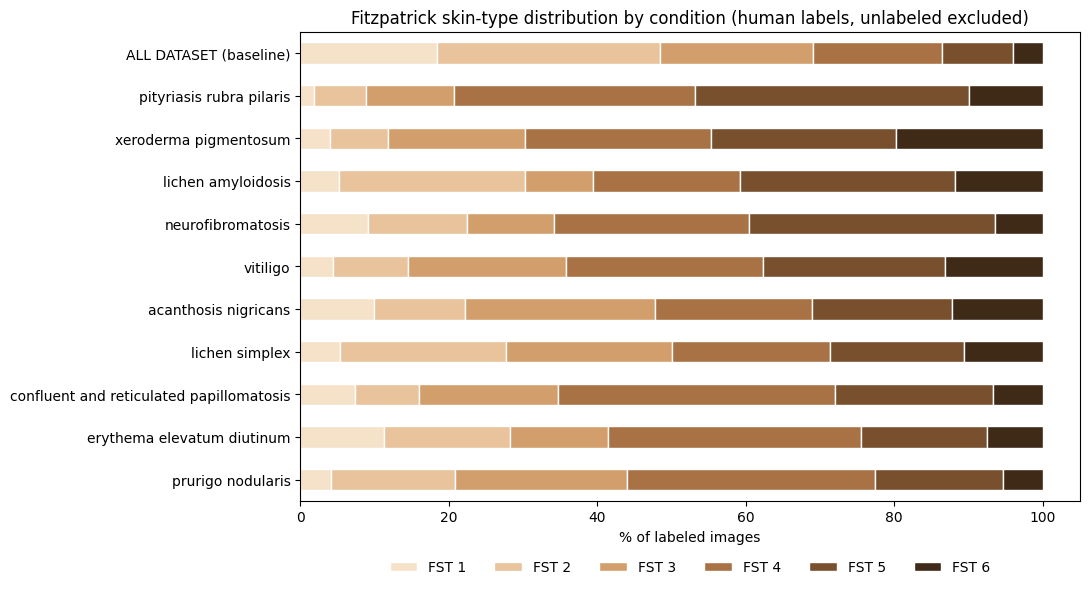

In [18]:
order = result.sort_values("dark_pct").disease
plot = result.set_index("disease").loc[order, [f"fst{f}_pct" for f in FST]]
plot.columns = [f"FST {f}" for f in FST]
# add the dataset baseline as a reference bar
plot.loc["ALL DATASET (baseline)"] = (ref_pct * 100).values
colors = ["#f6e2c9", "#e8c39b", "#d29e6c", "#a97245", "#78502d", "#3f2a18"]
ax = plot.plot(kind="barh", stacked=True, figsize=(11, 6), color=colors, edgecolor="white")
ax.set_xlabel("% of labeled images"); ax.set_ylabel("")
ax.set_title("Fitzpatrick skin-type distribution by condition (human labels, unlabeled excluded)")
ax.legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
plt.tight_layout(); plt.show()